# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional
expression notebook follows signatures directly.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the
ends of its trajectory. Per the **derive-don't-inherit** mandate we do **not** inherit that
pair: we score a candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the
mesenchymal/neural-crest FOXC and PRRX families** — along *this* trajectory, gated on
detectable expression, and classify each factor by **its own** pseudotime position (sign of
the Spearman correlation and the early-vs-late mean), then report the root and terminus
markers the data actually supports. VIM is a mesenchymal marker, not a transcription factor,
so it is excluded. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 108979 | pseudotime range 0.0 -> 11.74


### Classify the detectable EMT-TFs by pseudotime position (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root)
vs late (terminus) pseudotime tercile, and Spearman correlation with pseudotime. A factor is
**root-localised** if it skews early (mean_early > mean_late, i.e. negative rho) and
**terminus-localised** if it skews late (positive rho). We take the detectable factors (above
a 3% expression floor) and read the root marker (most negative rho) and the terminus marker
(most positive rho) **from their actual signs** — not by taking the extremes of the ranking
regardless of sign. If no detectable factor localises to a given end, we report that
explicitly rather than mislabel the least-early factor as "terminus".

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))

FLOOR = 0.03
ok = df[df.frac_expr > FLOOR]
root_side = ok[ok.rho_vs_t < 0].sort_values('rho_vs_t')            # most root-specific first
term_side = ok[ok.rho_vs_t > 0].sort_values('rho_vs_t')            # most terminus-specific last
print(f'\ndetectable (>{int(FLOOR*100)}%) EMT-TFs:', list(ok['TF']))
print('root-localised (rho<0):', list(root_side['TF']),
      '| terminus-localised (rho>0):', list(term_side['TF']))

root_tf = root_side.iloc[0]['TF'] if len(root_side) else None
term_tf = term_side.iloc[-1]['TF'] if len(term_side) else None
if root_tf is not None and term_tf is not None:
    disp = [root_tf, term_tf]; axis_kind = 'root-terminus'
    print(f'\nderived root/terminus pair: {root_tf} (root) <-> {term_tf} (terminus)')
else:
    # one end has no detectable EMT-TF: show the two most-detectable factors from the
    # populated end, honestly labelled (no false "terminus" tag)
    side = root_side if term_tf is None else term_side
    end_lbl = 'root/early' if term_tf is None else 'terminus/late'
    disp = list(side.sort_values('frac_expr', ascending=False)['TF'])[:2]
    axis_kind = 'root-only' if term_tf is None else 'terminus-only'
    print(f'\nno detectable EMT-TF localises to the {"terminus" if term_tf is None else "root"} '
          f'above the {int(FLOOR*100)}% floor; the detectable factors are {end_lbl}-loaded.')
    print(f'displaying the two most-detectable {end_lbl} markers: {disp}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.064       0.019      0.007    -0.093    EARLY(root)
 SNAI1      0.071       0.015      0.008    -0.073    EARLY(root)
 PRRX2      0.022       0.006      0.003    -0.054    EARLY(root)
  ZEB1      0.011       0.003      0.001    -0.043    EARLY(root)
  ZEB2      0.014       0.005      0.003    -0.039    EARLY(root)
 PRRX1      0.026       0.005      0.004    -0.033    EARLY(root)
 FOXC2      0.006       0.001      0.001    -0.019 LATE(terminus)
 SNAI2      0.001       0.000      0.000    -0.010 LATE(terminus)
TWIST1      0.010       0.002      0.002    -0.009 LATE(terminus)
TWIST2      0.000       0.000      0.000    -0.003 LATE(terminus)

detectable (>3%) EMT-TFs: ['FOXC1', 'SNAI1']
root-localised (rho<0): ['FOXC1', 'SNAI1'] | terminus-localised (rho>0): []

no detectable EMT-TF localises to the terminus above the 3% floor; the detectable factors are root/early-loaded.
displaying the two most-detectable roo

### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right. Categorical overlay of thresholded
expressers on a grey manifold (not a continuous single-gene colormap). Each factor is
thresholded at the upper quartile of expression among its expressing cells, so only the
strongest expressers show. When the data support a genuine root↔terminus pair the two are
coloured blue (root) / red (terminus); when only one end has a detectable EMT-TF the two
displayed factors are the most-detectable markers of that same end (coloured blue / orange),
with the title stating they co-localise — the honest read for this dataset, where both
detectable factors are root-loaded and no EMT-TF clears the floor at the neural-crest
terminus.

overlay thresholds (upper quartile among expressers): {'SNAI1': 0.226, 'FOXC1': 0.257} | cells shown: {'SNAI1': 1932, 'FOXC1': 1754}
SNAI1: 7.1% expressing; 1932 shown (upper quartile), mean pseudotime of shown cells = 0.39 (all cells = 0.48)
FOXC1: 6.4% expressing; 1754 shown (upper quartile), mean pseudotime of shown cells = 0.32 (all cells = 0.48)
interpretation: both displayed factors have shown-cell mean pseudotime below the population mean -> root-loaded; no detectable EMT-TF marks the neural-crest terminus.
saved expression.pdf


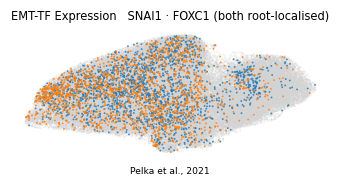

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in disp:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in disp}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in disp},
      '| cells shown:', {g: int(sel[g].sum()) for g in disp})
if axis_kind == 'root-terminus':
    palette = {disp[0]:'tab:blue', disp[1]:'tab:red'}
    title = f'EMT-TF Expression   {disp[0]} (root) · {disp[1]} (terminus)'
else:
    palette = {disp[0]:'tab:blue', disp[1]:'tab:orange'}
    endword = 'root' if axis_kind=='root-only' else 'terminus'
    title = f'EMT-TF Expression   {disp[0]} · {disp[1]} (both {endword}-localised)'
order = sorted(disp, key=lambda g: -int(sel[g].sum()))   # abundant first, sparse on top
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=4, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=palette[g], size=6, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(title, size=7.5)
ax.text(.5,-.14,'Pelka et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in disp:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('interpretation: both displayed factors have shown-cell mean pseudotime below the '
      'population mean -> root-loaded; no detectable EMT-TF marks the neural-crest terminus.')
print('saved expression.pdf')